# Supervised Learning on Census Income - 2026-10-23 - KriAgu7298

In [2]:
# Step 2: Load and Explore the Census Income Dataset

import pandas as pd
from datetime import datetime
from IPython.display import display, Markdown

student_id = "KriAgu7298"
todays_date = datetime.now().strftime("%Y-%m-%d")

display(Markdown("### Load and Explore the Dataset"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Load the dataset
data = pd.read_csv("census_income_dataset.csv")

# Display the first five rows
print("First Five Rows:")
display(data.head())

# Display dataset information
print("\nDataset Information:")
data.info()

# Display descriptive statistics
print("\nDescriptive Statistics:")
display(data.describe(include="all"))




### Load and Explore the Dataset

Date: 2026-10-23

Student ID: KriAgu7298

First Five Rows:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       47879 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      47876 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48568 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB

Descriptive Statistics:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
count,48842.000000,47879,4.884200e+04,48842,48842.000000,48842,47876,48842,48842,48842,48842.000000,48842.000000,48842.000000,48568,48842
unique,NaN,9,NaN,16,NaN,7,15,6,5,2,NaN,NaN,NaN,42,4
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,33906,NaN,15784,NaN,22379,6172,19716,41762,32650,NaN,NaN,NaN,43832,24720
mean,38.643585,NaN,1.896641e+05,NaN,10.078089,NaN,NaN,NaN,NaN,NaN,1079.067626,87.502314,40.422382,NaN,NaN
std,13.710510,NaN,1.056040e+05,NaN,2.570973,NaN,NaN,NaN,NaN,NaN,7452.019058,403.004552,12.391444,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.175505e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.781445e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.376420e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [3]:
# Step 3: Preprocess the Census Income Dataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

display(Markdown("### Step 3: Data Preprocessing"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Make a copy of the original dataset
data = data.copy()

# Check for missing values, including '?' placeholders
data = data.replace(r'^\s*\?\s*$', pd.NA, regex=True)

print("Missing Values Before Cleaning:")
print(data.isnull().sum())

# Remove rows containing missing values
data = data.dropna().copy()

# Identify and remove duplicate rows
print("\nDuplicate Rows:", data.duplicated().sum())
data = data.drop_duplicates().copy()

# Clean income labels and convert to binary
# Remove periods found in some income values
data['income'] = data['income'].astype(str).str.strip().str.rstrip('.')

data['income'] = data['income'].apply(
    lambda x: 1 if x == '>50K' else 0
)

# Separate features and target
X = data.drop('income', axis=1)
y = data['income']

# One-hot encode categorical features
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Split into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Standardize features for KNN
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Display results
print("\nPreprocessing Complete!")
print("Remaining Rows:", len(data))
print("Features After Encoding:", X.shape[1])
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("\nIncome Class Distribution:")
print(y.value_counts())


### Step 3: Data Preprocessing

Date: 2026-10-23

Student ID: KriAgu7298

Missing Values Before Cleaning:
age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
dtype: int64

Duplicate Rows: 28

Preprocessing Complete!
Remaining Rows: 45194
Features After Encoding: 96
Training Samples: 31635
Testing Samples: 13559

Income Class Distribution:
income
0    33988
1    11206
Name: count, dtype: int64


In [4]:
# Step 4: Implement K-Nearest Neighbors Algorithm

from sklearn.neighbors import KNeighborsClassifier

display(Markdown("### Step 4: K-Nearest Neighbors Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Initialize the KNN classifier with 5 neighbors
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model using the training data
knn.fit(X_train, y_train)

# Predict income categories using the test data
y_pred = knn.predict(X_test)

# Display prediction results
print("KNN Model Training Complete!")
print("\nFirst 10 Predicted Income Values:")
print(y_pred[:10])

print("\nFirst 10 Actual Income Values:")
print(y_test.iloc[:10].values)

print("\nTotal Predictions:", len(y_pred))


### Step 4: K-Nearest Neighbors Model

Date: 2026-10-23

Student ID: KriAgu7298

KNN Model Training Complete!

First 10 Predicted Income Values:
[0 1 1 1 0 0 1 0 0 0]

First 10 Actual Income Values:
[1 1 1 0 0 0 1 0 0 0]

Total Predictions: 13559


In [5]:
# Step 5: Evaluate the KNN Model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

display(Markdown("### Step 5: KNN Model Evaluation"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Display results
print("KNN Model Performance (Before Tuning)")
print("-------------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Display detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Income <=50K", "Income >50K"],
    zero_division=0
))


### Step 5: KNN Model Evaluation

Date: 2026-10-23

Student ID: KriAgu7298

KNN Model Performance (Before Tuning)
-------------------------------------
Accuracy:  0.8200
Precision: 0.6557
Recall:    0.5773
F1 Score:  0.6140

Confusion Matrix:
[[9178 1019]
 [1421 1941]]

Classification Report:
              precision    recall  f1-score   support

Income <=50K       0.87      0.90      0.88     10197
 Income >50K       0.66      0.58      0.61      3362

    accuracy                           0.82     13559
   macro avg       0.76      0.74      0.75     13559
weighted avg       0.81      0.82      0.82     13559



In [6]:
# Step 6: GridSearchCV Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

display(Markdown("### Step 6: GridSearchCV Hyperparameter Tuning"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Define the parameter grid
param_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

# Initialize the KNN model
knn_grid = KNeighborsClassifier()

# Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=knn_grid,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Fit GridSearchCV to the training data
grid_search.fit(X_train, y_train)

# Get the best model and parameters
best_knn = grid_search.best_estimator_

# Refit the best model
best_knn.fit(X_train, y_train)

# Make predictions using the tuned model
y_pred_tuned = best_knn.predict(X_test)

# Display results
print("\nGridSearchCV Complete!")
print("--------------------------------")
print("Best Parameters:", grid_search.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")
print("Tuned Model:", best_knn)
print("Total Test Predictions:", len(y_pred_tuned))


### Step 6: GridSearchCV Hyperparameter Tuning

Date: 2026-10-23

Student ID: KriAgu7298

Fitting 5 folds for each of 24 candidates, totalling 120 fits

GridSearchCV Complete!
--------------------------------
Best Parameters: {'metric': 'manhattan', 'n_neighbors': 9, 'weights': 'uniform'}
Best Cross-Validation Accuracy: 0.8269
Tuned Model: KNeighborsClassifier(metric='manhattan', n_neighbors=9)
Total Test Predictions: 13559


In [7]:
# Step 7: Evaluate the Tuned KNN Model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

display(Markdown("### Step 7: Tuned KNN Model Evaluation"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Calculate tuned model performance metrics
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_precision = precision_score(y_test, y_pred_tuned, zero_division=0)
tuned_recall = recall_score(y_test, y_pred_tuned, zero_division=0)
tuned_f1 = f1_score(y_test, y_pred_tuned, zero_division=0)

# Display tuned model results
print("Tuned KNN Model Performance")
print("-------------------------------------")
print(f"Accuracy:  {tuned_accuracy:.4f}")
print(f"Precision: {tuned_precision:.4f}")
print(f"Recall:    {tuned_recall:.4f}")
print(f"F1 Score:  {tuned_f1:.4f}")

# Display confusion matrix
print("\nTuned Model Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

# Display classification report
print("\nTuned Model Classification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Income <=50K", "Income >50K"],
    zero_division=0
))

# Compare original and tuned model performance
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Original KNN": [accuracy, precision, recall, f1],
    "Tuned KNN": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1
    ]
})

comparison["Difference"] = (
    comparison["Tuned KNN"] - comparison["Original KNN"]
)

print("\nOriginal vs. Tuned KNN Comparison:")
display(comparison.round(4))

print("\nBest Hyperparameters:")
print(grid_search.best_params_)


### Step 7: Tuned KNN Model Evaluation

Date: 2026-10-23

Student ID: KriAgu7298

Tuned KNN Model Performance
-------------------------------------
Accuracy:  0.8304
Precision: 0.6910
Recall:    0.5714
F1 Score:  0.6255

Tuned Model Confusion Matrix:
[[9338  859]
 [1441 1921]]

Tuned Model Classification Report:
              precision    recall  f1-score   support

Income <=50K       0.87      0.92      0.89     10197
 Income >50K       0.69      0.57      0.63      3362

    accuracy                           0.83     13559
   macro avg       0.78      0.74      0.76     13559
weighted avg       0.82      0.83      0.82     13559


Original vs. Tuned KNN Comparison:


,Metric,Original KNN,Tuned KNN,Difference
0,Accuracy,0.8200,0.8304,0.0103
1,Precision,0.6557,0.6910,0.0353
2,Recall,0.5773,0.5714,-0.0059
3,F1 Score,0.6140,0.6255,0.0115



Best Hyperparameters:
{'metric': 'manhattan', 'n_neighbors': 9, 'weights': 'uniform'}


### Step 8: KNN Model Visualizations

Date: 2026-10-23

Student ID: KriAgu7298

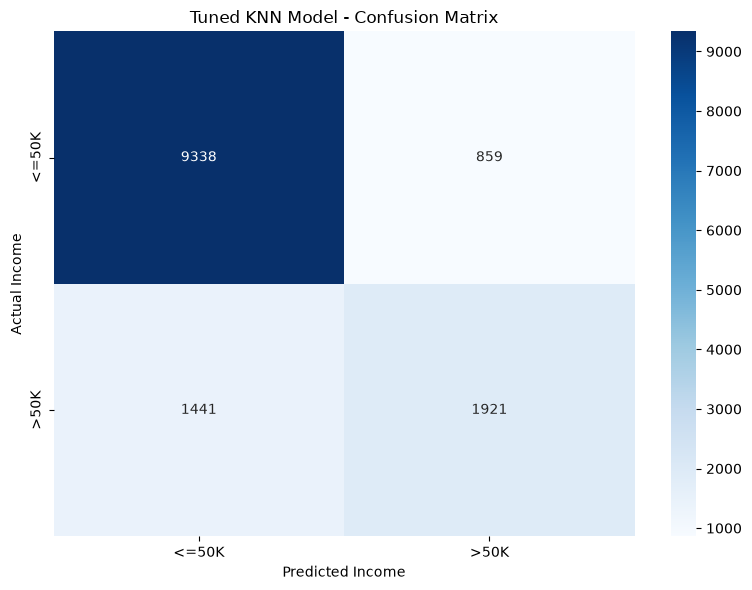

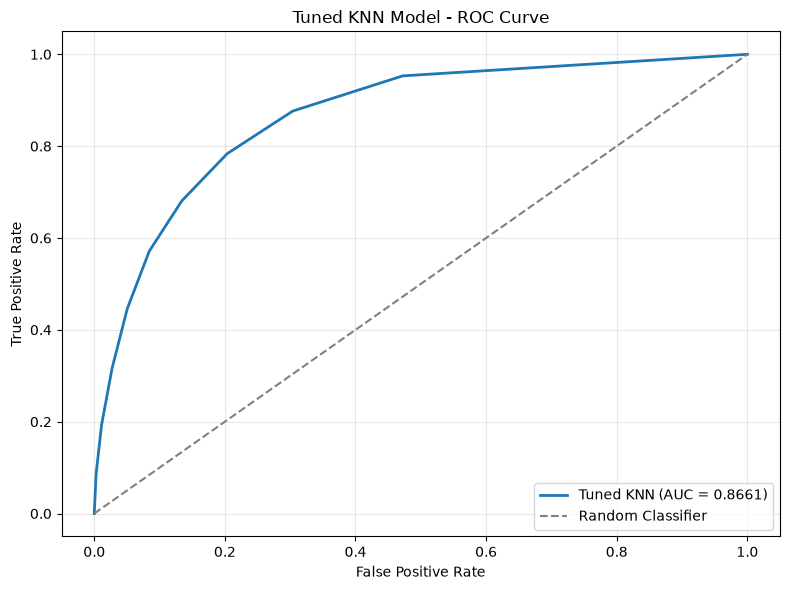

ROC AUC Score: 0.8661


In [8]:
# Step 8: Visualize KNN Model Results

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

display(Markdown("### Step 8: KNN Model Visualizations"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# -----------------------------------
# Visualization 1: Confusion Matrix
# -----------------------------------

cm = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['<=50K', '>50K'],
    yticklabels=['<=50K', '>50K']
)

plt.xlabel('Predicted Income')
plt.ylabel('Actual Income')
plt.title('Tuned KNN Model - Confusion Matrix')
plt.tight_layout()
plt.show()

# -----------------------------------
# Visualization 2: ROC Curve and AUC
# -----------------------------------

# Get predicted probabilities for income >50K
y_prob_tuned = best_knn.predict_proba(X_test)[:, 1]

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_tuned)
auc_score = roc_auc_score(y_test, y_prob_tuned)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Tuned KNN (AUC = {auc_score:.4f})',
    linewidth=2
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Tuned KNN Model - ROC Curve')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"ROC AUC Score: {auc_score:.4f}")


In [9]:
# Step 9: Results for Written Analysis

display(Markdown("### Step 9: Analyze and Interpret"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

print("ORIGINAL KNN MODEL")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

print("\nTUNED KNN MODEL")
print(f"Accuracy: {tuned_accuracy:.4f}")
print(f"Precision: {tuned_precision:.4f}")
print(f"Recall: {tuned_recall:.4f}")
print(f"F1 Score: {tuned_f1:.4f}")

print("\nBEST HYPERPARAMETERS")
print(grid_search.best_params_)


### Step 9: Analyze and Interpret

Date: 2026-10-23

Student ID: KriAgu7298

ORIGINAL KNN MODEL
Accuracy: 0.8200
Precision: 0.6557
Recall: 0.5773
F1 Score: 0.6140

TUNED KNN MODEL
Accuracy: 0.8304
Precision: 0.6910
Recall: 0.5714
F1 Score: 0.6255

BEST HYPERPARAMETERS
{'metric': 'manhattan', 'n_neighbors': 9, 'weights': 'uniform'}
